# 03 Convergence, posterior predictive checks, sensitivity, model comparison and results

This notebook goes with the report sections on convergence, posterior predictive checks, sensitivity analysis and model comparison, and gives the H1-H3 results for the conclusion. 

LOADS SAVED FITS, run after update of 02

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import arviz as az
import bambi as bmb
import pymc as pm
from scipy import stats

import icebreak_common as ic

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
REGION_COLORS = {"south": "#2a6fbb", "central": "#3a9e6f", "north": "#c4572a"}
MODEL_LABELS = {"M0_pooled": "M0 pooled", "M1_hier_linear": "M1 hier. linear",
                "M2_hier_broken": "M2 hier. broken stick",
                "M3_hier_broken_region": "M3 M2 + regional years"}
NAMES = list(ic.FORMULAS)
LFO_SPLIT = 2005

d = ic.load_breakup(recent_only=True)
y = d[ic.RESPONSE].to_numpy()

models = {n: ic.build_model(n, d) for n in NAMES}
for m in models.values():
    m.build()
idatas = {n: az.from_netcdf(ic.RES_DIR / f"{n}.nc") for n in NAMES}
print("loaded:", list(idatas))

loaded: ['M0_pooled', 'M1_hier_linear', 'M2_hier_broken', 'M3_hier_broken_region']


## 1. Convergence diagnostics
R-hat and ESS are computed over all parameters, including every lake and year effect. We want R-hat < 1.01, bulk and tail ESS > 400 and no divergent transitions.

In [3]:
diag = {}
for n in NAMES:
    diag[n] = ic.diagnostics_table(idatas[n])
for path in sorted(ic.RES_DIR.glob("*_prior*.nc")) + sorted(ic.RES_DIR.glob("*_lfo*.nc")) \
        + sorted(ic.RES_DIR.glob("M3s_spline.nc")):
    diag[path.stem] = ic.diagnostics_table(az.from_netcdf(path))
diag_tab = pd.DataFrame(diag).T
diag_tab["ok"] = ((diag_tab["max R-hat"] < 1.01) & (diag_tab["min bulk-ESS"] > 400)
                  & (diag_tab["min tail-ESS"] > 400) & (diag_tab["divergences"] == 0))
diag_tab.round(3)

,max R-hat,min bulk-ESS,min tail-ESS,divergences,parameters,ok
M0_pooled,1.00,2432.0,2454.0,0.0,6.0,True
M1_hier_linear,1.10,31.0,112.0,0.0,520.0,False
M2_hier_broken,1.02,203.0,275.0,0.0,521.0,False
M3_hier_broken_region,1.00,1147.0,1841.0,0.0,1232.0,True
M0_pooled_prior0.5,1.00,2537.0,2428.0,0.0,6.0,True
M0_pooled_prior2.0,1.00,2347.0,2024.0,0.0,6.0,True
M1_hier_linear_prior0.5,1.08,44.0,107.0,0.0,520.0,False
M1_hier_linear_prior2.0,1.10,27.0,41.0,0.0,520.0,False
M2_hier_broken_prior0.5,1.02,329.0,395.0,0.0,521.0,False
M2_hier_broken_prior2.0,1.04,128.0,312.0,0.0,521.0,False


Rank plots for the main parameters of the most complex model. If the histograms look uniform for every chain, the chains are exploring the same distribution.

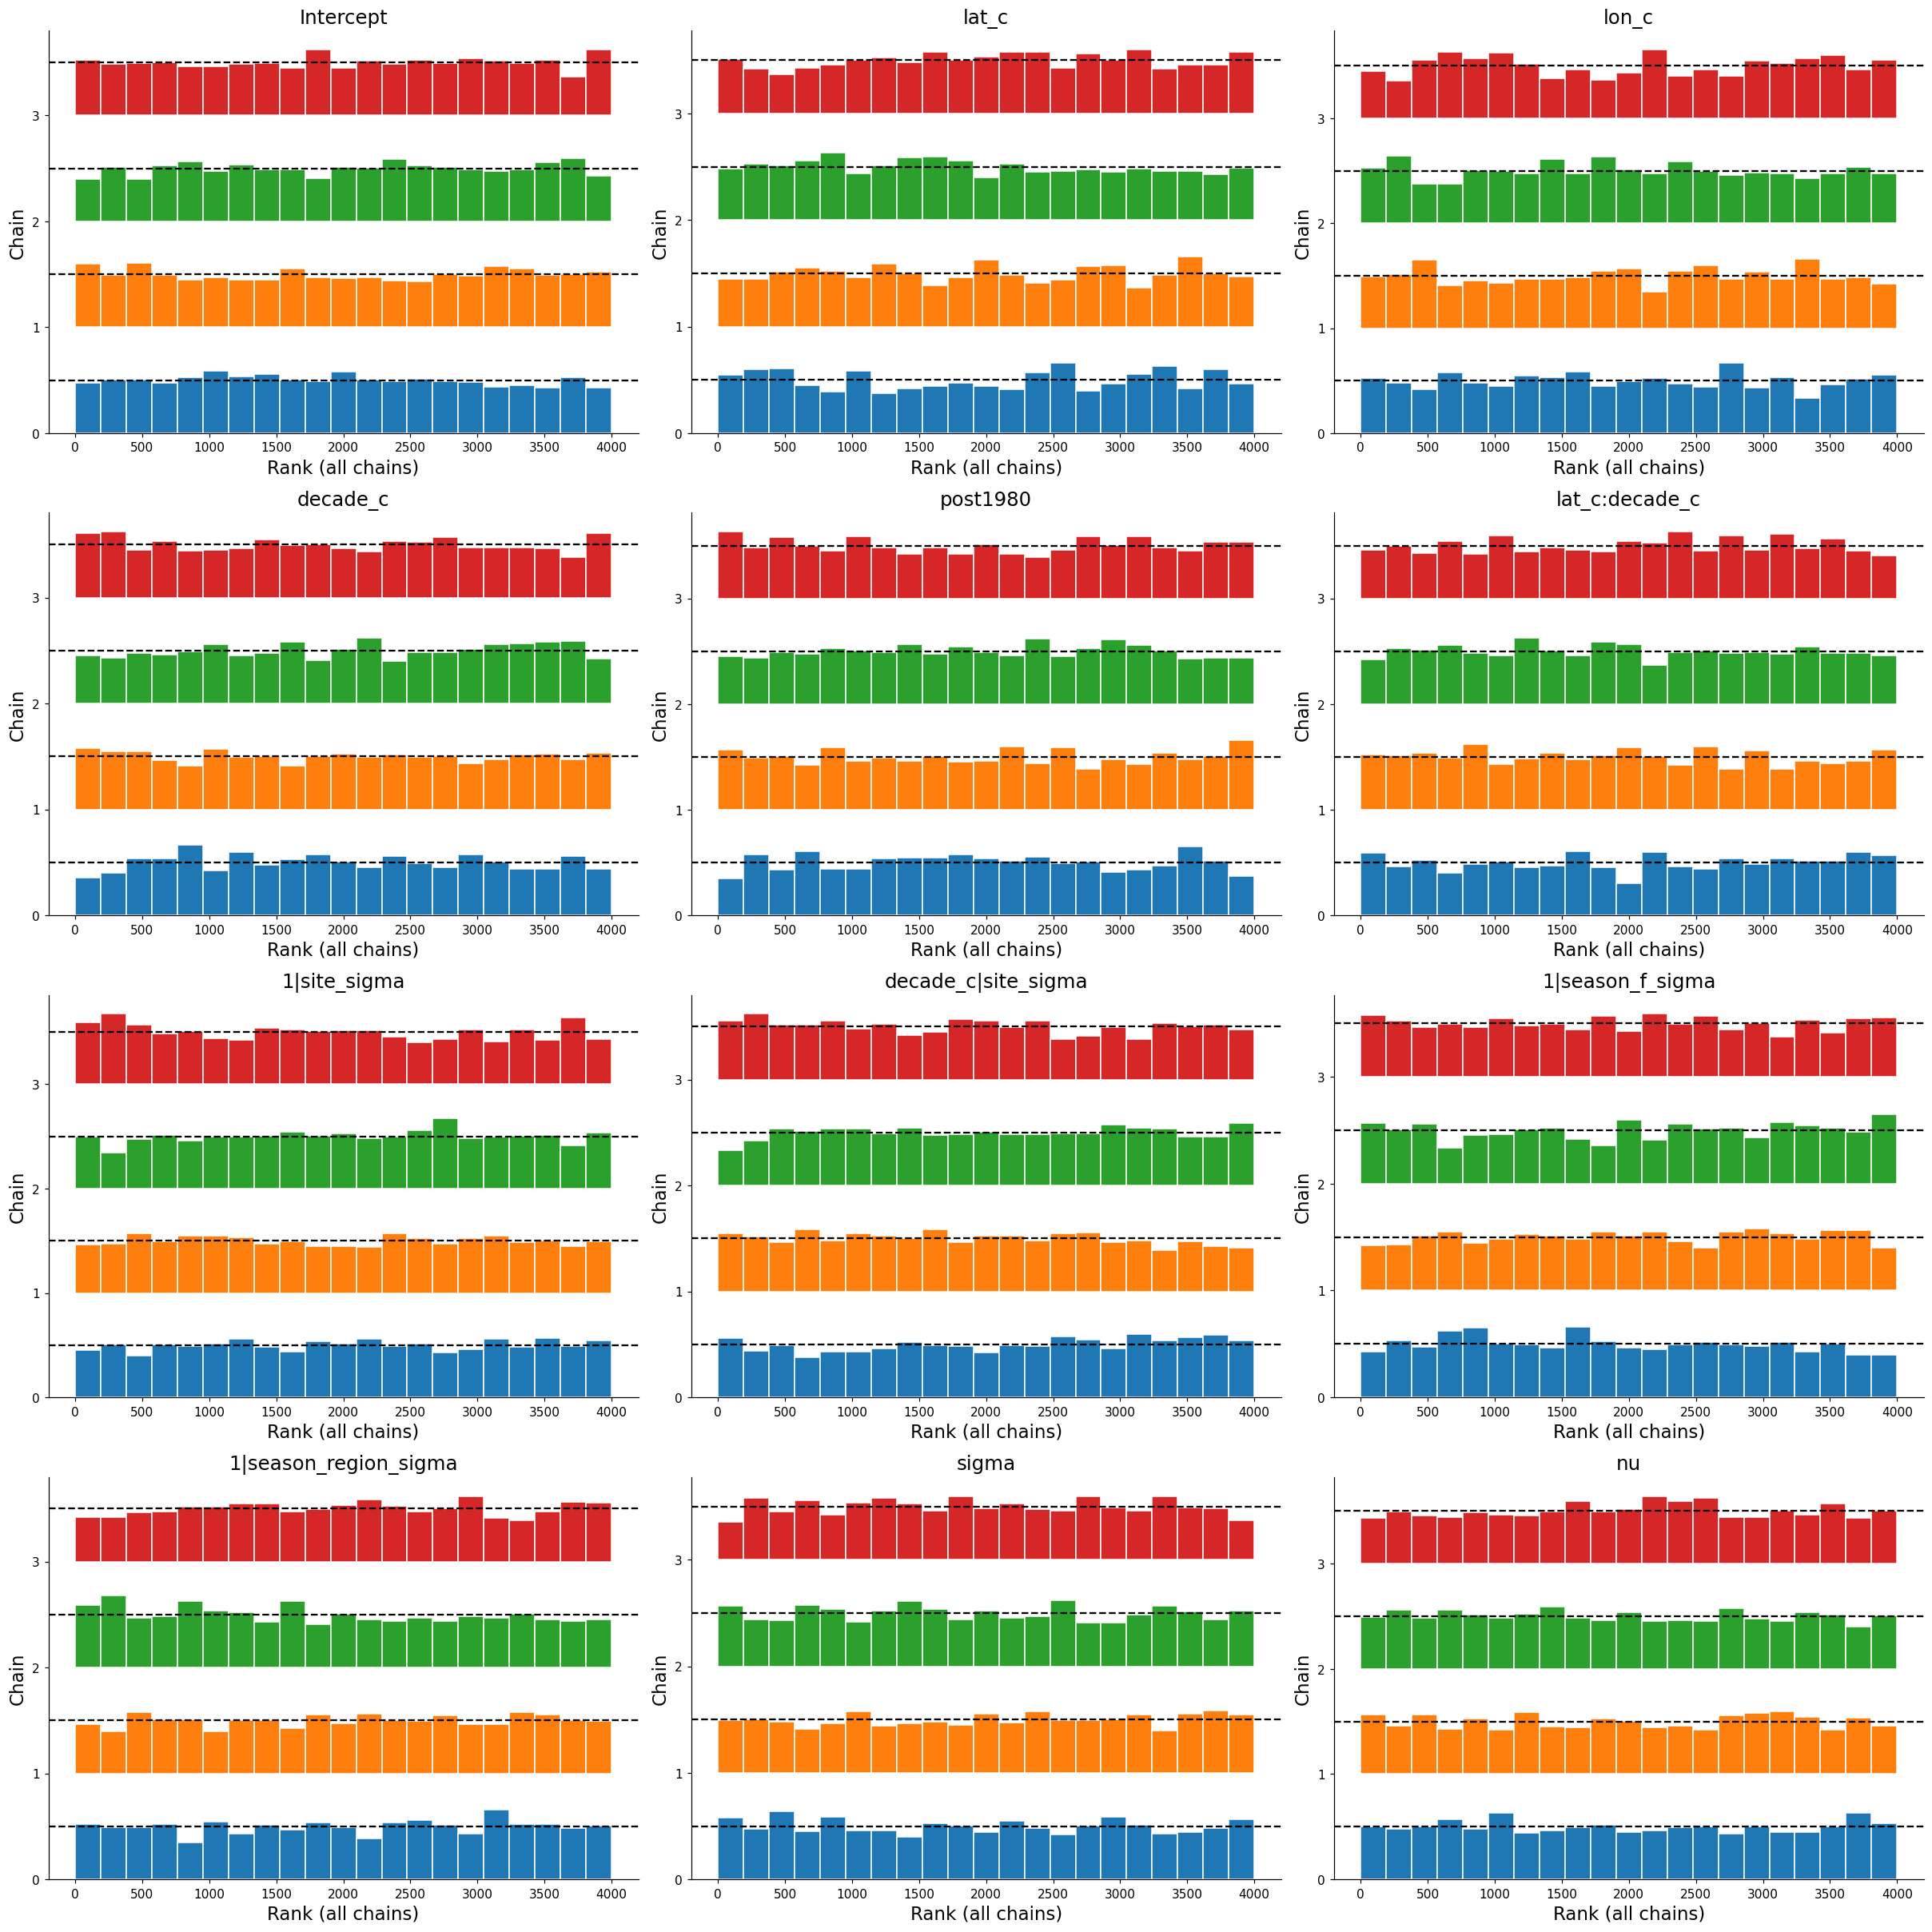

In [4]:
key = ["Intercept", "lat_c", "lon_c", "decade_c", "post1980", "lat_c:decade_c",
       "1|site_sigma", "decade_c|site_sigma", "1|season_f_sigma", "1|season_region_sigma",
       "sigma", "nu"]
key_m3 = [k for k in key if k in idatas["M3_hier_broken_region"].posterior]
az.plot_rank(idatas["M3_hier_broken_region"], var_names=key_m3)
plt.tight_layout()
plt.savefig(ic.FIG_DIR / "figA_rank_M3.png", bbox_inches="tight")
plt.show()

## 2. Posterior summaries of the scalar parameters

In [5]:
summ = {}
for n in NAMES:
    s = az.summary(idatas[n], var_names=ic.scalar_vars(idatas[n]), hdi_prob=0.9, kind="stats")
    summ[n] = s["mean"].round(2).astype(str) + " [" + s["hdi_5%"].round(2).astype(str) + ", " \
        + s["hdi_95%"].round(2).astype(str) + "]"
summary_tab = pd.DataFrame(summ).reindex(key).rename(columns=MODEL_LABELS).fillna("-")
summary_tab.to_csv(ic.RES_DIR / "posterior_summary.csv")
summary_tab

,M0 pooled,M1 hier. linear,M2 hier. broken stick,M3 M2 + regional years
Intercept,"128.17 [127.98, 128.4]","127.94 [126.59, 129.4]","131.57 [129.16, 134.15]","131.58 [129.27, 133.97]"
lat_c,"4.52 [4.43, 4.59]","4.4 [4.14, 4.66]","4.38 [4.09, 4.65]","4.51 [4.2, 4.8]"
lon_c,"0.19 [0.1, 0.28]","0.01 [-0.3, 0.31]","0.0 [-0.31, 0.35]","0.05 [-0.25, 0.37]"
decade_c,"-1.15 [-1.2, -1.09]","-1.1 [-1.41, -0.78]","-0.45 [-0.93, 0.05]","-0.41 [-0.9, 0.02]"
post1980,-,-,"-2.15 [-3.45, -0.99]","-2.26 [-3.4, -1.05]"
lat_c:decade_c,-,"0.07 [0.04, 0.1]","0.07 [0.04, 0.1]","0.1 [0.05, 0.14]"
1|site_sigma,-,"3.14 [2.66, 3.61]","3.15 [2.66, 3.64]","3.14 [2.67, 3.64]"
decade_c|site_sigma,-,"0.21 [0.17, 0.26]","0.22 [0.17, 0.26]","0.24 [0.19, 0.29]"
1|season_f_sigma,-,"7.56 [6.83, 8.3]","7.26 [6.48, 7.97]","6.45 [5.69, 7.22]"
1|season_region_sigma,-,-,-,"3.93 [3.57, 4.27]"


## 3. Posterior predictive checks
The outcome is continuous with many distinct values, so kernel density overlays are fine. We also use test statistics aimed at the parts of the model that matter for our questions:
1. Nationwide decade means: does the trend have the right shape? (M1 vs M2)
2. Correlation of yearly mean anomalies between regions: does the whole country really share one year effect? (M1/M2 vs M3)
3. Within-site SD by region: is the spread right in each region?
4. LOO-PIT: are the leave-one-out predictive distributions calibrated?

To save memory, the checks use every 4th draw (1000 draws).

In [6]:
thin = {
    n: idatas[n].sel(draw=slice(None, None, 4))
    for n in NAMES
}

yrep = {}
predictions = {}

for n in NAMES:
    pp = models[n].predict(
        thin[n],
        kind="response",
        include_group_specific=True,
        inplace=False
    )

    predictions[n] = pp

    yrep[n] = (
        pp.posterior_predictive[ic.RESPONSE]
        .stack(sample=("chain", "draw"))
        .transpose("sample", ...)
        .values
    )

print("Posterior predictive shapes:")
print({n: v.shape for n, v in yrep.items()})

Posterior predictive shapes:
{'M0_pooled': (1000, 6093), 'M1_hier_linear': (1000, 6093), 'M2_hier_broken': (1000, 6093), 'M3_hier_broken_region': (1000, 6093)}


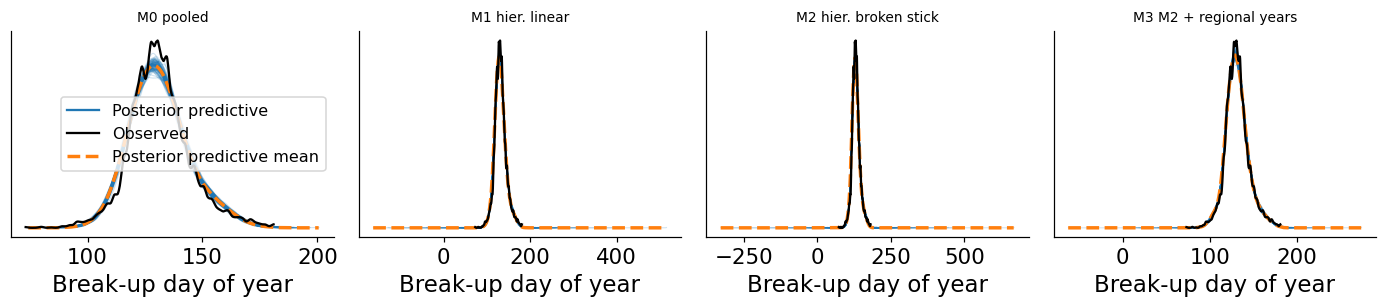

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(13, 2.9), sharey=True)

for ax, n in zip(axes, NAMES):
    az.plot_ppc(
        predictions[n],
        num_pp_samples=100,
        ax=ax,
        legend=(n == NAMES[0])
    )
    ax.set_title(MODEL_LABELS[n], fontsize=9)
    ax.set_xlabel("Break-up day of year")

fig.tight_layout()
fig.savefig(ic.FIG_DIR / "fig7_ppc_density.png", bbox_inches="tight")
plt.show()

In [9]:
def group_matrix(labels):
    """N x K matrix whose columns average over each group."""
    codes, uniq = pd.factorize(labels)
    G = np.zeros((len(labels), len(uniq)))
    G[np.arange(len(labels)), codes] = 1.0
    return G / G.sum(axis=0, keepdims=True), uniq

decade = (d.season // 10 * 10).to_numpy()
G_dec, dec_levels = group_matrix(decade)
order = np.argsort(dec_levels)
dec_levels = dec_levels[order]
G_dec = G_dec[:, order]

G_sr, sr_levels = group_matrix(d.season_region.to_numpy())
sr_season = np.array([int(s.split("_")[0]) for s in sr_levels])
sr_region = np.array([s.split("_")[1] for s in sr_levels])
seasons = np.sort(np.unique(sr_season))

G_site, site_levels = group_matrix(d.site.to_numpy())
site_idx = pd.factorize(d.site.to_numpy())[0]
site_region = d.groupby("site").region.first().reindex(site_levels).to_numpy()
n_site = np.bincount(site_idx)

def region_corr(Y):
    """Y (S, N) -> (S, 3) correlations of yearly regional mean anomalies:
    south-central, south-north, central-north."""
    Y = np.atleast_2d(Y)
    cell = Y @ G_sr                                     # (S, cells)
    mat = np.full((Y.shape[0], len(seasons), 3), np.nan)
    s_pos = np.searchsorted(seasons, sr_season)
    r_pos = np.array([ic.REGION_LABELS.index(r) for r in sr_region])
    mat[:, s_pos, r_pos] = cell
    out = []
    for a, b in [(0, 1), (0, 2), (1, 2)]:
        ok = ~np.isnan(mat[0, :, a]) & ~np.isnan(mat[0, :, b])
        xa, xb = mat[:, ok, a], mat[:, ok, b]
        xa = xa - xa.mean(1, keepdims=True)
        xb = xb - xb.mean(1, keepdims=True)
        out.append((xa * xb).sum(1) / np.sqrt((xa ** 2).sum(1) * (xb ** 2).sum(1)))
    return np.stack(out, axis=1)

def within_site_sd_by_region(Y):
    Y = np.atleast_2d(Y)
    m = Y @ G_site
    v = ((Y - m[:, site_idx]) ** 2) @ G_site * n_site / (n_site - 1)
    sd = np.sqrt(v)
    return np.stack([sd[:, site_region == r].mean(1) for r in ic.REGION_LABELS], axis=1)

obs = {"dec": (y @ G_dec), "corr": region_corr(y)[0], "sd": within_site_sd_by_region(y)[0]}
rep = {n: {"dec": yrep[n] @ G_dec, "corr": region_corr(yrep[n]),
           "sd": within_site_sd_by_region(yrep[n])} for n in NAMES}

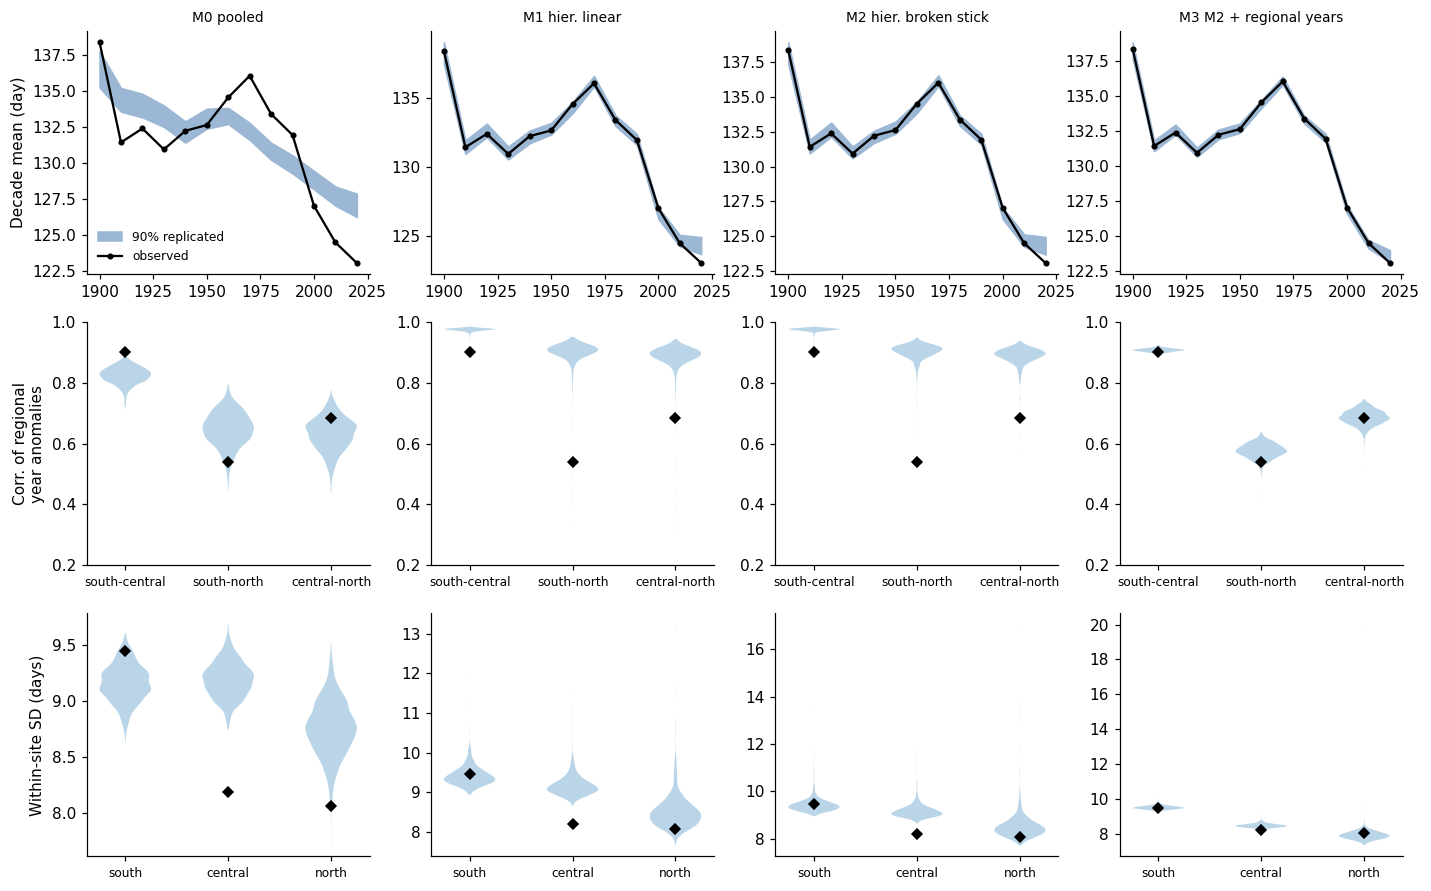

,corr south-central,corr south-north,corr central-north,SD south,SD central,SD north,decades inside 90% band
M0 pooled,0.0,0.967,0.15,0.045,1.0,0.997,2/13
M1 hier. linear,0.999,0.995,0.992,0.359,1.0,0.936,12/13
M2 hier. broken stick,0.998,1.0,0.998,0.375,1.0,0.921,12/13
M3 M2 + regional years,0.794,0.93,0.528,0.683,0.996,0.224,12/13


In [10]:
fig, axes = plt.subplots(3, 4, figsize=(13, 8.2))
corr_lab = ["south-central", "south-north", "central-north"]
for j, n in enumerate(NAMES):
    ax = axes[0, j]
    lo, hi = np.percentile(rep[n]["dec"], [5, 95], axis=0)
    ax.fill_between(dec_levels, lo, hi, color="#9bb7d4", label="90% replicated")
    ax.plot(dec_levels, obs["dec"], "k.-", label="observed")
    ax.set_title(MODEL_LABELS[n], fontsize=9)
    ax.set_ylabel("Decade mean (day)" if j == 0 else "")
    if j == 0:
        ax.legend(frameon=False, fontsize=8)
    ax = axes[1, j]
    ax.violinplot(rep[n]["corr"], positions=range(3), showextrema=False)
    ax.plot(range(3), obs["corr"], "kD", ms=5)
    ax.set_xticks(range(3), corr_lab, fontsize=8)
    ax.set_ylim(0.2, 1.0)
    ax.set_ylabel("Corr. of regional\nyear anomalies" if j == 0 else "")
    ax = axes[2, j]
    ax.violinplot(rep[n]["sd"], positions=range(3), showextrema=False)
    ax.plot(range(3), obs["sd"], "kD", ms=5)
    ax.set_xticks(range(3), ic.REGION_LABELS, fontsize=8)
    ax.set_ylabel("Within-site SD (days)" if j == 0 else "")
fig.tight_layout()
fig.savefig(ic.FIG_DIR / "fig8_ppc_test_stats.png", bbox_inches="tight")
plt.show()

# posterior predictive p-values for the test statistics
ppp = {}
for n in NAMES:
    row = {}
    for i, lab in enumerate(corr_lab):
        row[f"corr {lab}"] = np.mean(rep[n]["corr"][:, i] >= obs["corr"][i])
    for i, lab in enumerate(ic.REGION_LABELS):
        row[f"SD {lab}"] = np.mean(rep[n]["sd"][:, i] >= obs["sd"][i])
    inside = (obs["dec"] >= np.percentile(rep[n]["dec"], 5, axis=0)) & \
             (obs["dec"] <= np.percentile(rep[n]["dec"], 95, axis=0))
    row["decades inside 90% band"] = f"{inside.sum()}/{len(inside)}"
    ppp[MODEL_LABELS[n]] = row
pd.DataFrame(ppp).T

Posterior predictive p-values near 0 or 1 mean the model cannot reproduce that feature of the data. What we expect to see (compare with the output and rewrite if it differs):
- M0 has no year effects, so it cannot reproduce how strongly lakes move together from year to year.
- M1's straight line misses the flat early period and the faster decline after about 1980, so decade means fall outside the band at both ends. M2 is meant to fix this.
- M1 and M2 give all regions one shared year effect, so their replicated correlations between regions are around 0.9, while the observed south-north correlation is about 0.5. M3's regional year effects should fix this.

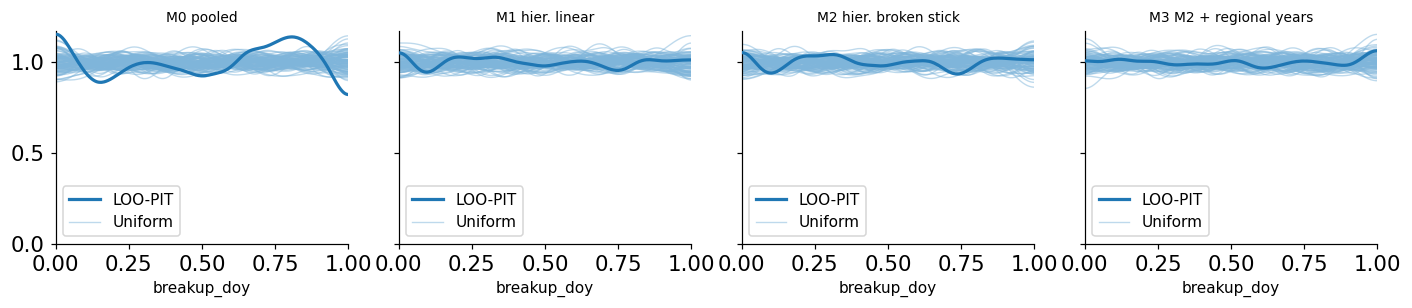

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(13, 2.9), sharey=True)

for ax, n in zip(axes, NAMES):
    az.plot_loo_pit(
        predictions[n],
        y=ic.RESPONSE,
        ax=ax
    )
    ax.set_title(MODEL_LABELS[n], fontsize=9)

fig.tight_layout()
fig.savefig(ic.FIG_DIR / "fig9_loo_pit.png", bbox_inches="tight")
plt.show()

## 4. Model comparison with PSIS-LOO
elpd_loo is the expected log predictive density for a new lake-year. We judge differences against their standard error; a difference of more than about 2-4 SE is clear.

In [14]:
loos = {}
for n in NAMES:
    loos[n] = az.loo(idatas[n], pointwise=True)
    k = loos[n].pareto_k.values
    print(f"{MODEL_LABELS[n]:28s} elpd_loo = {loos[n].elpd_loo:9.1f} (SE {loos[n].se:5.1f}), "
          f"p_loo = {loos[n].p_loo:6.1f}, Pareto k > 0.7: {np.sum(k > 0.7)}")

cmp = az.compare({MODEL_LABELS[n]: idatas[n] for n in NAMES}, ic="loo")
cmp.to_csv(ic.RES_DIR / "loo_compare.csv")
cmp

M0 pooled                    elpd_loo =  -21648.5 (SE  59.1), p_loo =    6.7, Pareto k > 0.7: 0
M1 hier. linear              elpd_loo =  -16890.2 (SE  84.7), p_loo =  283.3, Pareto k > 0.7: 0
M2 hier. broken stick        elpd_loo =  -16889.9 (SE  84.7), p_loo =  282.9, Pareto k > 0.7: 0
M3 M2 + regional years       elpd_loo =  -15392.8 (SE  80.3), p_loo =  583.9, Pareto k > 0.7: 0


,rank,elpd_loo,p_loo,elpd_diff,weight,se,dse,warning,scale
M3 M2 + regional years,0,-15392.799343,583.879323,0.000000,9.449139e-01,80.346308,0.000000,False,log
M2 hier. broken stick,1,-16889.945037,282.909706,1497.145694,1.212951e-18,84.668718,66.151531,False,log
M1 hier. linear,2,-16890.244889,283.342898,1497.445547,5.293711e-02,84.705440,66.171024,False,log
M0 pooled,3,-21648.489778,6.713646,6255.690435,2.148962e-03,59.073310,85.292596,False,log


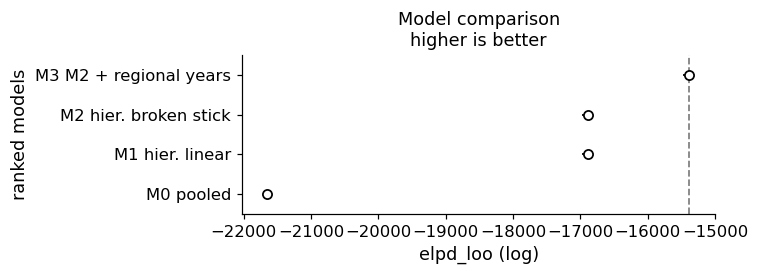

In [15]:
az.plot_compare(cmp, insample_dev=False, figsize=(7, 2.6))
plt.tight_layout()
plt.savefig(ic.FIG_DIR / "fig10_loo_compare.png", bbox_inches="tight")
plt.show()

### Leave-future-out: predicting unseen years (2006-2026)
The models fitted to seasons up to 2005 predict every lake-year in 2006-2026. The models know nothing about the test years' weather, so their year effects are drawn from the fitted population distribution.

In [16]:
d_train = d[d.season <= LFO_SPLIT].reset_index(drop=True)
d_test = d[d.season > LFO_SPLIT].reset_index(drop=True)
lfo_lpd = {}
for n in NAMES:
    path = ic.RES_DIR / f"{n}_lfo{LFO_SPLIT}.nc"
    if not path.exists():
        print("missing", path)
        continue
    m_tr = ic.build_model(n, d_train)
    m_tr.build()
    lfo_lpd[n] = ic.pointwise_lpd(m_tr, az.from_netcdf(path), d_test)

if lfo_lpd:
    best = max(lfo_lpd, key=lambda n: lfo_lpd[n].sum())
    rows = []
    for n, l in lfo_lpd.items():
        diff = l - lfo_lpd[best]
        rows.append({"model": MODEL_LABELS[n], "elpd (2006-2026)": l.sum(),
                     "SE": np.sqrt(len(l)) * l.std(),
                     "diff to best": diff.sum(), "SE of diff": np.sqrt(len(l)) * diff.std(),
                     "mean lpd per obs": l.mean()})
    lfo_tab = pd.DataFrame(rows).sort_values("elpd (2006-2026)", ascending=False).round(1)
    lfo_tab.to_csv(ic.RES_DIR / "lfo_compare.csv", index=False)
    display(lfo_tab)

,model,elpd (2006-2026),SE,diff to best,SE of diff,mean lpd per obs
3,M3 M2 + regional years,-4100.3,27.5,0.0,0.0,-3.6
2,M2 hier. broken stick,-4149.8,28.3,-49.5,3.9,-3.6
1,M1 hier. linear,-4421.7,41.8,-321.5,19.0,-3.9
0,M0 pooled,-4565.0,49.2,-464.8,27.5,-4.0


Test observations from the same year share a year effect and are not independent, so these SEs are somewhat too small. We use this comparison alongside PSIS-LOO, not as the main criterion.

## 5. Prior sensitivity
(a) Refits with every prior scale multiplied by 0.5 and by 2 (fitted in notebook 02). If the posterior means and intervals of the parameters behind H1-H3 barely move, the priors are not driving the conclusions.

In [17]:
sens_rows = []
for n in NAMES:
    for sc in [0.5, 1.0, 2.0]:
        path = ic.RES_DIR / (f"{n}.nc" if sc == 1.0 else f"{n}_prior{sc}.nc")
        if not path.exists():
            continue
        post = az.from_netcdf(path).posterior
        for v in key:
            if v in post:
                x = ic.draws(post, v)
                sens_rows.append({"model": MODEL_LABELS[n], "parameter": v, "prior scale": sc,
                                  "mean": x.mean(), "q5": np.percentile(x, 5),
                                  "q95": np.percentile(x, 95)})
sens = pd.DataFrame(sens_rows)
sens_wide = sens.pivot_table(index=["model", "parameter"], columns="prior scale",
                             values="mean").round(2)
sens_wide

prior scale                                      0.5     1.0     2.0
model                  parameter                                    
M0 pooled              Intercept              128.18  128.17  128.16
                       decade_c                -1.15   -1.15   -1.15
                       lat_c                    4.51    4.52    4.52
                       lon_c                    0.19    0.19    0.18
                       nu                      21.27   24.14   26.81
                       sigma                    8.04    8.08    8.11
M1 hier. linear        1|season_f_sigma         7.53    7.56    7.53
                       1|site_sigma             3.13    3.14    3.19
                       Intercept              128.14  127.95  127.85
                       decade_c                -1.07   -1.10   -1.11
                       decade_c|site_sigma      0.22    0.21    0.22
                       lat_c                    4.39    4.40    4.38
                       lat_c:decade_c           0.07    0.07    0.07
                       lon_c                    0.03    0.01    0.02
                       nu                       2.75    2.75    2.75
                       sigma                    2.56    2.56    2.56
M2 hier. broken stick  1|season_f_sigma         7.28    7.26    7.33
                       1|site_sigma             3.15    3.15    3.16
                       Intercept              131.08  131.57  131.49
                       decade_c                -0.53   -0.45   -0.46
                       decade_c|site_sigma      0.22    0.22    0.22
                       lat_c                    4.39    4.38    4.40
                       lat_c:decade_c           0.07    0.07    0.07
                       lon_c                    0.01    0.00    0.00
                       nu                       2.75    2.76    2.75
                       post1980                -1.86   -2.15   -2.12
                       sigma                    2.56    2.56    2.56
M3 M2 + regional years 1|season_f_sigma         6.39    6.45    6.45
                       1|season_region_sigma    3.91    3.93    3.93
                       1|site_sigma             3.13    3.14    3.14
                       Intercept              131.14  131.58  131.75
                       decade_c                -0.49   -0.41   -0.38
                       decade_c|site_sigma      0.24    0.24    0.24
                       lat_c                    4.48    4.51    4.51
                       lat_c:decade_c           0.10    0.10    0.10
                       lon_c                    0.05    0.05    0.05
                       nu                       3.28    3.29    3.29
                       post1980                -1.99   -2.26   -2.36
                       sigma                    2.08    2.08    2.08

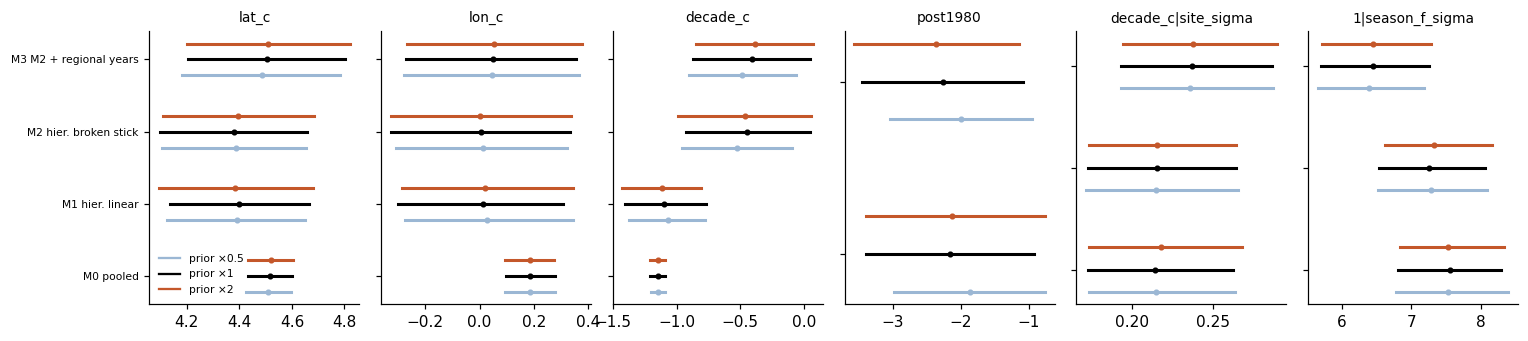

In [18]:
focus = ["lat_c", "lon_c", "decade_c", "post1980", "decade_c|site_sigma", "1|season_f_sigma"]
fig, axes = plt.subplots(1, len(focus), figsize=(14, 3.2))
for ax, v in zip(axes, focus):
    sub = sens[sens.parameter == v]
    for i, (mod, g) in enumerate(sub.groupby("model", sort=False)):
        for j, (_, r) in enumerate(g.iterrows()):
            yy = i + (j - 1) * 0.22
            ax.plot([r.q5, r.q95], [yy, yy], color=["#9bb7d4", "k", "#c4572a"][j], lw=2)
            ax.plot(r["mean"], yy, "o", ms=3, color=["#9bb7d4", "k", "#c4572a"][j])
    ax.set_yticks(range(sub.model.nunique()), sub.model.unique() if v == focus[0] else [""] *
                  sub.model.nunique(), fontsize=7)
    ax.set_title(v, fontsize=9)
axes[0].plot([], [], color="#9bb7d4", label="prior ×0.5")
axes[0].plot([], [], color="k", label="prior ×1")
axes[0].plot([], [], color="#c4572a", label="prior ×2")
axes[0].legend(frameon=False, fontsize=7, loc="lower left")
fig.tight_layout()
fig.savefig(ic.FIG_DIR / "fig11_prior_sensitivity.png", bbox_inches="tight")
plt.show()

(b) Power-scaling sensitivity (Kallioinen et al. 2023; az.psens). The prior, and separately the likelihood, is raised to a power close to 1, and we measure how much each posterior changes. A prior sensitivity above about 0.05 combined with low likelihood sensitivity points to a prior-data conflict or a prior that is too informative. We only power-scale the priors of the population-level parameters and SDs, not the standard-normal offsets of the non-centred group effects. 

In [19]:
def psens_table(model, idata, var_names):
    try:
        from pymc.stats import compute_log_prior
    except ImportError:
        compute_log_prior = pm.compute_log_prior
    pmodel = model.backend.model
    # power-scale only the priors of population-level parameters and SDs
    prior_vars = [rv.name for rv in pmodel.free_RVs if not rv.name.endswith("_offset")]
    idt = idata.copy()
    compute_log_prior(idt, var_names=prior_vars, model=pmodel, extend_inferencedata=True)
    pri = az.psens(idt, component="prior", var_names=var_names)
    lik = az.psens(idt, component="likelihood", var_names=var_names)
    return pd.DataFrame({"prior": {v: float(pri[v]) for v in var_names},
                         "likelihood": {v: float(lik[v]) for v in var_names}})

ps = {}
for n in NAMES:
    try:
        vn = [v for v in key if v in idatas[n].posterior]
        ps[MODEL_LABELS[n]] = psens_table(models[n], idatas[n], vn)
    except Exception as e:      # older PyMC/ArviZ
        print(f"psens skipped for {n}: {type(e).__name__}: {e}")
if ps:
    display(pd.concat(ps, axis=1).round(3))

Output()

Output()

Output()

Output()

M0 pooled            M1 hier. linear             \
                          prior likelihood           prior likelihood   
Intercept                 0.013      0.088           0.007      0.113   
lat_c                     0.009      0.081           0.005      0.082   
lon_c                     0.002      0.101           0.001      0.046   
decade_c                  0.008      0.091           0.010      0.088   
sigma                     0.044      0.083           0.003      0.450   
nu                        0.107      0.117           0.005      0.338   
lat_c:decade_c              NaN        NaN           0.001      0.105   
1|site_sigma                NaN        NaN           0.002      0.151   
decade_c|site_sigma         NaN        NaN           0.001      0.269   
1|season_f_sigma            NaN        NaN           0.005      0.071   
post1980                    NaN        NaN             NaN        NaN   
1|season_region_sigma       NaN        NaN             NaN        NaN   

                      M2 hier. broken stick            M3 M2 + regional years  \
                                      prior likelihood                  prior   
Intercept                             0.024      0.088                  0.021   
lat_c                                 0.003      0.057                  0.006   
lon_c                                 0.002      0.103                  0.001   
decade_c                              0.023      0.097                  0.021   
sigma                                 0.004      0.375                  0.003   
nu                                    0.005      0.332                  0.004   
lat_c:decade_c                        0.001      0.111                  0.004   
1|site_sigma                          0.003      0.085                  0.001   
decade_c|site_sigma                   0.001      0.266                  0.003   
1|season_f_sigma                      0.006      0.055                  0.006   
post1980                              0.030      0.085                  0.029   
1|season_region_sigma                   NaN        NaN                  0.004   

                                  
                      likelihood  
Intercept                  0.055  
lat_c                      0.073  
lon_c                      0.082  
decade_c                   0.080  
sigma                      0.633  
nu                         0.248  
lat_c:decade_c             0.085  
1|site_sigma               0.067  
decade_c|site_sigma        0.237  
1|season_f_sigma           0.117  
post1980                   0.086  
1|season_region_sigma      0.313

## 6. Results for the research questions
These results use the model that LOO and the predictive checks favour.

In [20]:
RESULT_MODEL = "M3_hier_broken_region"
post = idatas[RESULT_MODEL].posterior
P = {v: ic.draws(post, v) for v in key if v in post}

def summ(x, scale=1.0):
    x = np.asarray(x) * scale
    return f"{x.mean():.2f} [{np.percentile(x, 5):.2f}, {np.percentile(x, 95):.2f}]"

### H1: latitude and longitude

In [21]:
ROPE_LON = 1.0   # days per degree east considered practically negligible
h1 = pd.Series({
    "β_lat, days per degree north (90% CI)": summ(P["lat_c"]),
    "β_lat, days per 100 km north": summ(P["lat_c"], 100 / 111.0),
    "P(β_lat > 0)": f"{np.mean(P['lat_c'] > 0):.3f}",
    "β_lon, days per degree east (90% CI)": summ(P["lon_c"]),
    f"P(|β_lon| < {ROPE_LON}) (ROPE)": f"{np.mean(np.abs(P['lon_c']) < ROPE_LON):.3f}",
    "Lake-level SD τ_a (days)": summ(P["1|site_sigma"]),
})
h1

β_lat, days per degree north (90% CI)     4.51 [4.20, 4.80]
β_lat, days per 100 km north              4.06 [3.79, 4.33]
P(β_lat > 0)                                          1.000
β_lon, days per degree east (90% CI)     0.05 [-0.27, 0.35]
P(|β_lon| < 1.0) (ROPE)                               1.000
Lake-level SD τ_a (days)                  3.14 [2.69, 3.68]
dtype: object

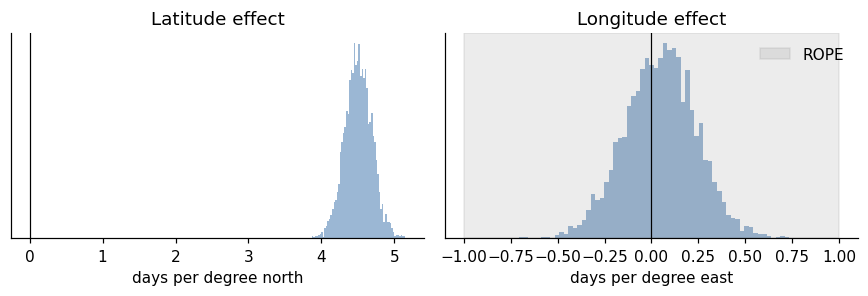

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(8, 2.8))
for ax, v, lab in zip(axes, ["lat_c", "lon_c"], ["days per degree north", "days per degree east"]):
    ax.hist(P[v], bins=60, color="#9bb7d4", density=True)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_xlabel(lab)
    ax.set_yticks([])
axes[1].axvspan(-ROPE_LON, ROPE_LON, color="grey", alpha=0.15, label="ROPE")
axes[1].legend(frameon=False)
axes[0].set_title("Latitude effect")
axes[1].set_title("Longitude effect")
fig.tight_layout()
fig.savefig(ic.FIG_DIR / "fig12_h1_lat_lon.png", bbox_inches="tight")
plt.show()

### H2: trend over time and the change after 1980
The population-level trend for a typical lake (site effect 0, longitude 26° E) at three latitudes, with year effects removed. Bands are 90% posterior intervals of the mean.

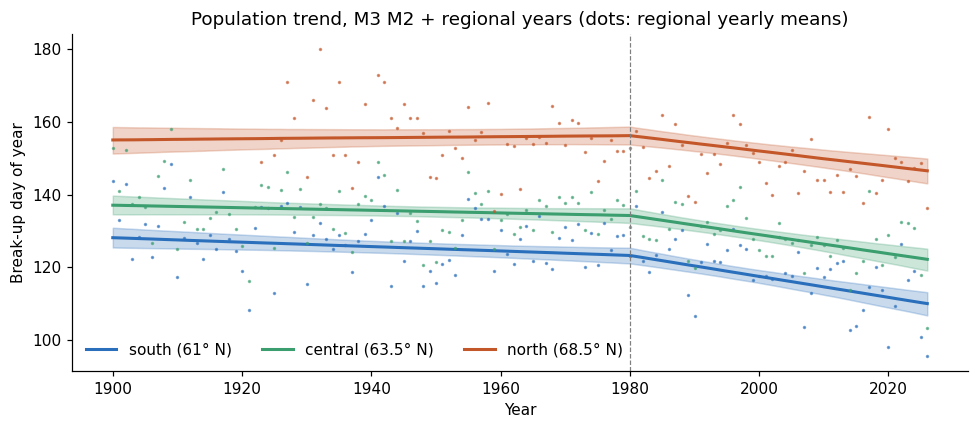

In [23]:
years = np.arange(1900, 2027)
xg = (years - 1990) / 10
pg = np.clip(years - ic.BREAK_YEAR, 0, None) / 10
lat_show = {"south (61° N)": 61.0, "central (63.5° N)": 63.5, "north (68.5° N)": 68.5}

def trend_draws(P, lat):
    lc = lat - ic.LAT_CENTER
    mu = (P["Intercept"][:, None] + P["lat_c"][:, None] * lc
          + (P["decade_c"][:, None] + P["lat_c:decade_c"][:, None] * lc) * xg[None, :])
    if "post1980" in P:
        mu = mu + P["post1980"][:, None] * pg[None, :]
    return mu

fig, ax = plt.subplots(figsize=(9, 4))
yr_mean = d.groupby(["region", "season"])[ic.RESPONSE].mean().reset_index()
for (lab, lat), reg in zip(lat_show.items(), ic.REGION_LABELS):
    mu = trend_draws(P, lat)
    lo, med, hi = np.percentile(mu, [5, 50, 95], axis=0)
    ax.fill_between(years, lo, hi, color=REGION_COLORS[reg], alpha=0.25)
    ax.plot(years, med, color=REGION_COLORS[reg], lw=2, label=lab)
    g = yr_mean[yr_mean.region == reg]
    ax.plot(g.season, g[ic.RESPONSE], ".", ms=2.5, color=REGION_COLORS[reg], alpha=0.6)
ax.axvline(ic.BREAK_YEAR, color="grey", ls="--", lw=0.8)
ax.set_xlabel("Year")
ax.set_ylabel("Break-up day of year")
ax.set_title(f"Population trend, {MODEL_LABELS[RESULT_MODEL]} (dots: regional yearly means)")
ax.legend(frameon=False, ncol=3)
fig.tight_layout()
fig.savefig(ic.FIG_DIR / "fig13_h2_trend.png", bbox_inches="tight")
plt.show()

In [24]:
slope_pre = P["decade_c"]
slope_post = P["decade_c"] + P.get("post1980", 0)
change_1980_2026 = slope_post * (2026 - 1980) / 10
h2 = pd.Series({
    "Trend before 1980, days/decade (lat 62.98°)": summ(slope_pre),
    "Trend after 1980, days/decade": summ(slope_post),
    "Change in slope after 1980 (β_p)": summ(P.get("post1980", np.zeros(1))),
    "P(trend after 1980 < trend before)": f"{np.mean(P.get('post1980', np.zeros(1)) < 0):.3f}",
    "P(trend after 1980 < 0)": f"{np.mean(slope_post < 0):.3f}",
    "Total change 1980 to 2026, days": summ(change_1980_2026),
    "Year-effect SD τ_u (days)": summ(P["1|season_f_sigma"]),
})
h2

Trend before 1980, days/decade (lat 62.98°)       -0.41 [-0.87, 0.05]
Trend after 1980, days/decade                    -2.68 [-3.53, -1.81]
Change in slope after 1980 (β_p)                 -2.26 [-3.45, -1.08]
P(trend after 1980 < trend before)                              0.999
P(trend after 1980 < 0)                                         1.000
Total change 1980 to 2026, days                -12.31 [-16.23, -8.32]
Year-effect SD τ_u (days)                           6.45 [5.70, 7.25]
dtype: object

Checking the 1980 breakpoint with the spline model (M3s): if the spline is roughly flat before about 1980 and falls after it, the broken stick is a fair summary.

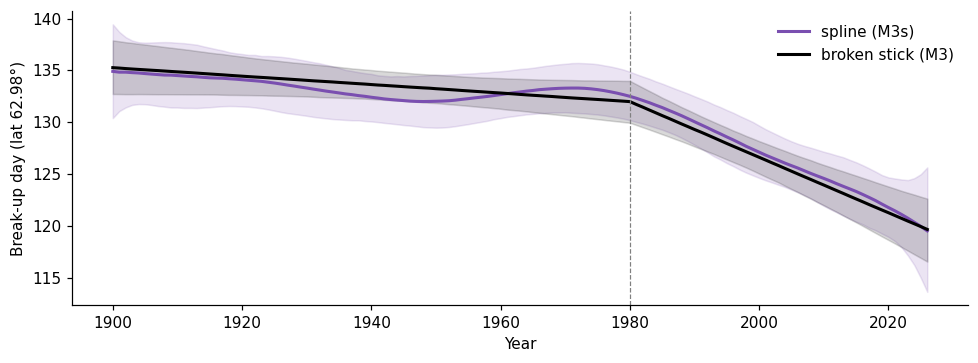

M3s elpd_loo = -15391.5 (SE 80.4); M3 elpd_loo = -15392.8
                 rank      elpd_loo       p_loo  elpd_diff  weight         se  \
M3s spline          0 -15391.461464  581.815923   0.000000     1.0  80.351497   
M3 broken stick     1 -15392.799343  583.879323   1.337879     0.0  80.346308   

                      dse  warning scale  
M3s spline       0.000000    False   log  
M3 broken stick  0.806436    False   log  


In [25]:
spath = ic.RES_DIR / "M3s_spline.nc"
if spath.exists():
    id_s = az.from_netcdf(spath)
    grid = pd.DataFrame({"season": years})
    s_names = ic.add_spline_basis(grid)
    B = grid[s_names].to_numpy()
    Ps = id_s.posterior
    mu_s = ic.draws(Ps, "Intercept")[:, None] + sum(
        ic.draws(Ps, nm)[:, None] * B[None, :, j] for j, nm in enumerate(s_names))
    mu_b = trend_draws(P, ic.LAT_CENTER)
    fig, ax = plt.subplots(figsize=(9, 3.4))
    for mu, lab, col in [(mu_s, "spline (M3s)", "#7a4fb0"), (mu_b, "broken stick (M3)", "k")]:
        lo, med, hi = np.percentile(mu, [5, 50, 95], axis=0)
        ax.fill_between(years, lo, hi, color=col, alpha=0.15)
        ax.plot(years, med, color=col, lw=2, label=lab)
    ax.axvline(ic.BREAK_YEAR, color="grey", ls="--", lw=0.8)
    ax.set_xlabel("Year")
    ax.set_ylabel("Break-up day (lat 62.98°)")
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(ic.FIG_DIR / "fig14_spline_vs_broken.png", bbox_inches="tight")
    plt.show()
    loo_s = az.loo(id_s)
    print(f"M3s elpd_loo = {loo_s.elpd_loo:.1f} (SE {loo_s.se:.1f}); "
          f"M3 elpd_loo = {loos['M3_hier_broken_region'].elpd_loo:.1f}")
    print(az.compare({"M3 broken stick": idatas["M3_hier_broken_region"], "M3s spline": id_s}))

### H3: do lakes differ in their trend?
A lake's trend is $\beta_x + \gamma\,\text{lat}_s + b_s$ before 1980; add $\beta_p$ for the trend after 1980.

In [26]:
h3 = pd.Series({
    "Between-lake SD of trend τ_b (days/decade)": summ(P["decade_c|site_sigma"]),
    "P(τ_b > 0.25 days/decade)": f"{np.mean(P['decade_c|site_sigma'] > 0.25):.3f}",
    "γ: trend change per degree north (days/decade)": summ(P["lat_c:decade_c"]),
    "P(γ > 0) (northern lakes change less)": f"{np.mean(P['lat_c:decade_c'] > 0):.3f}",
})
h3

Between-lake SD of trend τ_b (days/decade)        0.24 [0.19, 0.29]
P(τ_b > 0.25 days/decade)                                     0.311
γ: trend change per degree north (days/decade)    0.10 [0.06, 0.15]
P(γ > 0) (northern lakes change less)                         1.000
dtype: object

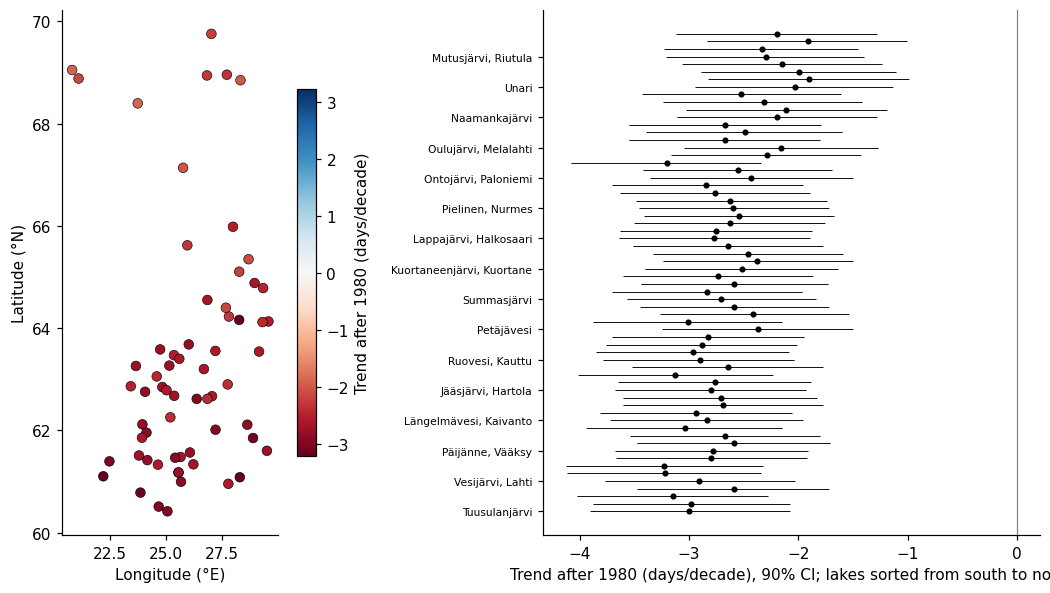

In [27]:
b_site = post["decade_c|site"]
site_dim = [dm for dm in b_site.dims if dm not in ("chain", "draw")][0]
bs = b_site.stack(sample=("chain", "draw")).transpose("sample", ...).values   # (S, J)
lev = [str(v) for v in b_site[site_dim].values]
info = d.groupby("site").agg(lat=("lat", "first"), lon=("lon", "first"),
                             name=("Nimi", "first")).reindex(lev)
lc = (info.lat.to_numpy() - ic.LAT_CENTER)[None, :]
trend_site = P["decade_c"][:, None] + P["lat_c:decade_c"][:, None] * lc + bs \
    + P.get("post1980", np.zeros_like(P["decade_c"]))[:, None]      # post-1980 trend
info["trend_post1980_mean"] = trend_site.mean(0)
info["q5"] = np.percentile(trend_site, 5, axis=0)
info["q95"] = np.percentile(trend_site, 95, axis=0)
info.to_csv(ic.RES_DIR / "site_trends.csv")

fig, axes = plt.subplots(1, 2, figsize=(10, 5.5), gridspec_kw={"width_ratios": [1, 1.3]})
lim = np.abs(info.trend_post1980_mean).max()
sc = axes[0].scatter(info.lon, info.lat, c=info.trend_post1980_mean, cmap="RdBu", vmin=-lim,
                     vmax=lim, s=40, edgecolor="k", linewidth=0.4)
fig.colorbar(sc, ax=axes[0], shrink=0.7, label="Trend after 1980 (days/decade)")
axes[0].set_xlabel("Longitude (°E)")
axes[0].set_ylabel("Latitude (°N)")
axes[0].set_aspect(1 / np.cos(np.deg2rad(64)))
o = info.sort_values("lat")
axes[1].errorbar(o.trend_post1980_mean, np.arange(len(o)),
                 xerr=[o.trend_post1980_mean - o.q5, o.q95 - o.trend_post1980_mean],
                 fmt="o", ms=3, color="k", elinewidth=0.6)
axes[1].axvline(0, color="grey", lw=0.8)
axes[1].set_yticks(np.arange(len(o))[::4], o.name.to_numpy()[::4], fontsize=7)
axes[1].set_xlabel("Trend after 1980 (days/decade), 90% CI; lakes sorted from south to north")
fig.tight_layout()
fig.savefig(ic.FIG_DIR / "fig15_h3_site_trends.png", bbox_inches="tight")
plt.show()

### RQ2: what to expect in the near future
The posterior predictive distribution of the break-up day for a typical lake in 2030 and 2040, if the post-1980 trend simply continues. Each new year gets a new national year effect (plus a new regional effect in M3) and Student-t noise, so the intervals include normal year-to-year weather. This is an extrapolation that rests entirely on the trend staying linear. We report it with that caveat and compare it with M1, which has no acceleration.

In [28]:
rng = np.random.default_rng(1)

def predictive_new_year(Pm, lat, year):
    S = len(Pm["Intercept"])
    lc = lat - ic.LAT_CENTER
    x = (year - 1990) / 10
    p = max(year - ic.BREAK_YEAR, 0) / 10
    mu = Pm["Intercept"] + Pm["lat_c"] * lc + (Pm["decade_c"] + Pm["lat_c:decade_c"] * lc) * x
    if "post1980" in Pm:
        mu = mu + Pm["post1980"] * p
    mu = mu + rng.normal(0, Pm["1|season_f_sigma"])
    if "1|season_region_sigma" in Pm:
        mu = mu + rng.normal(0, Pm["1|season_region_sigma"])
    mu = mu + rng.normal(0, Pm["1|site_sigma"])                # an arbitrary lake at that latitude
    return mu + Pm["sigma"] * rng.standard_t(Pm["nu"], size=S)

def doy_to_date(doy):
    return (pd.Timestamp("2030-01-01") + pd.Timedelta(days=float(doy) - 1)).strftime("%d %b")

rows = []
for mname in ["M1_hier_linear", RESULT_MODEL]:
    Pm = {v: ic.draws(idatas[mname].posterior, v) for v in key if v in idatas[mname].posterior}
    for lab, lat in lat_show.items():
        for yr_ in [2030, 2040]:
            yp = predictive_new_year(Pm, lat, yr_)
            q5, q50, q95 = np.percentile(yp, [5, 50, 95])
            rows.append({"model": MODEL_LABELS[mname], "latitude": lab, "year": yr_,
                         "median": f"{q50:.0f} ({doy_to_date(q50)})",
                         "90% interval": f"{q5:.0f}-{q95:.0f} ({doy_to_date(q5)} to {doy_to_date(q95)})"})
proj = pd.DataFrame(rows)
proj.to_csv(ic.RES_DIR / "projection_2030_2040.csv", index=False)
proj

,model,latitude,year,median,90% interval
0,M1 hier. linear,south (61° N),2030,114 (24 Apr),99-129 (09 Apr to 09 May)
1,M1 hier. linear,south (61° N),2040,113 (22 Apr),98-128 (07 Apr to 08 May)
2,M1 hier. linear,central (63.5° N),2030,126 (06 May),111-141 (20 Apr to 21 May)
3,M1 hier. linear,central (63.5° N),2040,125 (04 May),110-141 (19 Apr to 20 May)
4,M1 hier. linear,north (68.5° N),2030,150 (29 May),134-164 (13 May to 13 Jun)
5,M1 hier. linear,north (68.5° N),2040,149 (29 May),133-165 (13 May to 13 Jun)
6,M3 M2 + regional years,south (61° N),2030,109 (18 Apr),94-124 (03 Apr to 03 May)
7,M3 M2 + regional years,south (61° N),2040,106 (16 Apr),91-121 (31 Mar to 01 May)
8,M3 M2 + regional years,central (63.5° N),2030,121 (01 May),106-136 (15 Apr to 15 May)
9,M3 M2 + regional years,central (63.5° N),2040,119 (28 Apr),103-133 (13 Apr to 13 May)


## 7. Key numbers for the report

In [29]:
key_numbers = pd.concat([h1, h2, h3])
key_numbers.to_csv(ic.RES_DIR / "key_numbers.csv")
key_numbers.to_frame("value")

,value
"β_lat, days per degree north (90% CI)","4.51 [4.20, 4.80]"
"β_lat, days per 100 km north","4.06 [3.79, 4.33]"
P(β_lat > 0),1.000
"β_lon, days per degree east (90% CI)","0.05 [-0.27, 0.35]"
P(|β_lon| < 1.0) (ROPE),1.000
Lake-level SD τ_a (days),"3.14 [2.69, 3.68]"
"Trend before 1980, days/decade (lat 62.98°)","-0.41 [-0.87, 0.05]"
"Trend after 1980, days/decade","-2.68 [-3.53, -1.81]"
Change in slope after 1980 (β_p),"-2.26 [-3.45, -1.08]"
P(trend after 1980 < trend before),0.999


## 8. Robustness check: all 105 sites (optional)
Refit the preferred model on all sites, including those that closed before 2015, to check that changes in the station network are not driving the trend estimate.

In [ ]:
RUN_ALLSITES = False
if RUN_ALLSITES:
    d_all = ic.load_breakup(recent_only=False)
    m_all = ic.build_model(RESULT_MODEL, d_all)
    id_all = ic.fit_or_load(m_all, ic.RES_DIR / f"{RESULT_MODEL}_allsites.nc")
    print(ic.diagnostics_table(id_all))
    print(az.summary(id_all, var_names=[v for v in key if v in id_all.posterior], hdi_prob=0.9))

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, nu, Intercept, lat_c, lon_c, decade_c, post1980, lat_c:decade_c, 1|site_sigma, 1|site_offset, decade_c|site_sigma, decade_c|site_offset, 1|season_f_sigma, 1|season_f_offset, 1|season_region_sigma, 1|season_region_offset]
/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(
/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(
/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(


Output()

/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(


ValueError: Not enough samples to build a trace.